1) Инициализация

In [17]:
from common import load_data, split, prepare, outliers
X, y = load_data()
print(X.head()) # Проверка подгрузки данных

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import umap
from sklearn.manifold import TSNE

corr_threshold = 0.99 # correlation_threshold
seed = 42

         mean_1        mean_2    mean_3    mean_4        mean_5    mean_6  \
0 -3.014600e-07  8.260300e-06 -0.000012 -0.000002 -1.438600e-06 -0.000021   
1  2.913200e-06 -5.247700e-06  0.000003 -0.000006  2.778900e-06 -0.000004   
2 -2.951700e-06 -3.184000e-06 -0.000016 -0.000001 -1.575300e-06  0.000017   
3 -1.322600e-06  8.820100e-06 -0.000016 -0.000005 -7.282900e-07  0.000004   
4 -6.836600e-08  5.666300e-07 -0.000026 -0.000006 -7.940600e-07  0.000013   

     mean_7    mean_8    mean_9   mean_10  ...   kurt_3   kurt_4  kurt_5  \
0  0.031718  0.031710  0.031721 -0.032963  ...   6.0168 -0.63308  2.9646   
1  0.030804  0.030810  0.030806 -0.033520  ...   3.6048 -0.59314  7.6252   
2  0.032877  0.032880  0.032896 -0.029834  ...   5.8007 -0.63252  2.7784   
3  0.029410  0.029401  0.029417 -0.030156  ...  23.3960 -0.62289  6.5534   
4  0.030119  0.030119  0.030145 -0.031393  ...   5.0582 -0.63010  4.5155   

   kurt_6  kurt_7  kurt_8  kurt_9  kurt_10  kurt_11  kurt_12  
0  8.1198 -1.4961

2) Валидация данных

In [18]:
X, y = load_data()

missing_values = X.isna().sum().sum()
print(f"Количество пропусков: {missing_values}")

full_data = X.copy()
full_data['cls'] = y
duplicates = full_data.duplicated().sum()
print(f"Количество полных дубликатов строк: {duplicates}")

class_balance = full_data['cls'].value_counts()
print("\nКоличество записей в каждом классе:")
print(class_balance)

Количество пропусков: 0
Количество полных дубликатов строк: 0

Количество записей в каждом классе:
cls
1     5319
2     5319
3     5319
4     5319
5     5319
6     5319
7     5319
8     5319
9     5319
10    5319
11    5319
Name: count, dtype: int64


3) Карта корреляций

Столбцы, которые можно удалить: ['mean_8', 'mean_9', 'mean_11', 'mean_12', 'std_8', 'std_9', 'std_10', 'std_11', 'std_12', 'skew_8', 'skew_9', 'skew_11', 'skew_12', 'kurt_8', 'kurt_9', 'kurt_11', 'kurt_12']


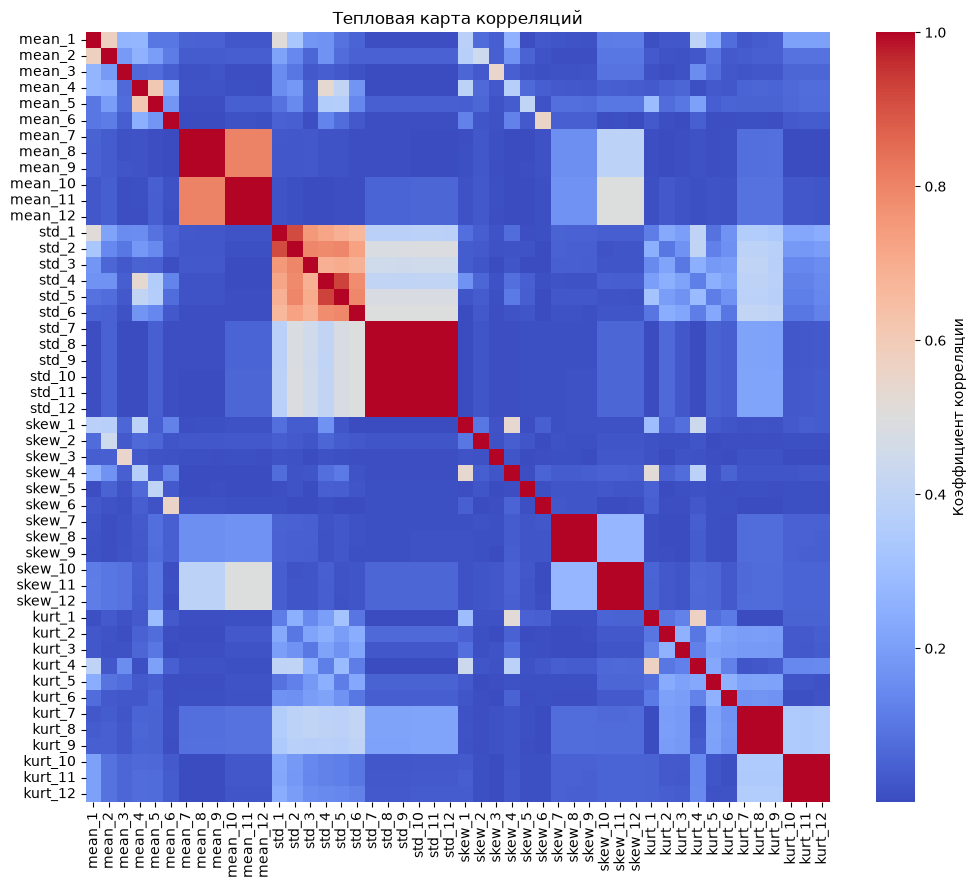

In [19]:
# Готовый сплит
X_train, X_test, y_train, y_test = split(X, y)

# Лишние столбцы ТОЛЬКО на train
corr_train_matrix = X_train.corr().abs()
# Только верхний треугольник без главной диагонали
upper_train = corr_train_matrix.where(pd.DataFrame(np.triu(np.ones(corr_train_matrix.shape), k=1).astype(bool), 
                                       index=corr_train_matrix.index, columns=corr_train_matrix.columns))
# Столбцы с корреляцией > corr_threshold
to_drop = [column for column in upper_train.columns if any(upper_train[column] > corr_threshold)]
print(f"Столбцы, которые можно удалить: {to_drop}")
# Удаляем их из train и test
X_train_reduced = X_train.drop(columns=to_drop)
X_test_reduced = X_test.drop(columns=to_drop)
corr_matrix = X.corr().abs() # Матрица корреляций

# Тепловая карта
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', cbar_kws={'label': 'Коэффициент корреляции'})
plt.title("Тепловая карта корреляций")
plt.savefig('correlation_heatmap.png') # Сохраняем в папку figures
plt.show()

# Готовая нормализация
X_train_scaled, X_test_scaled = prepare(X_train_reduced, X_test_reduced)

4) Проверка: метод локтя

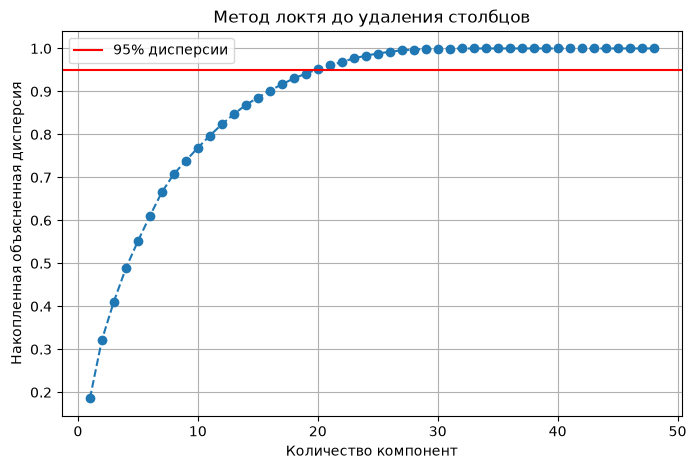

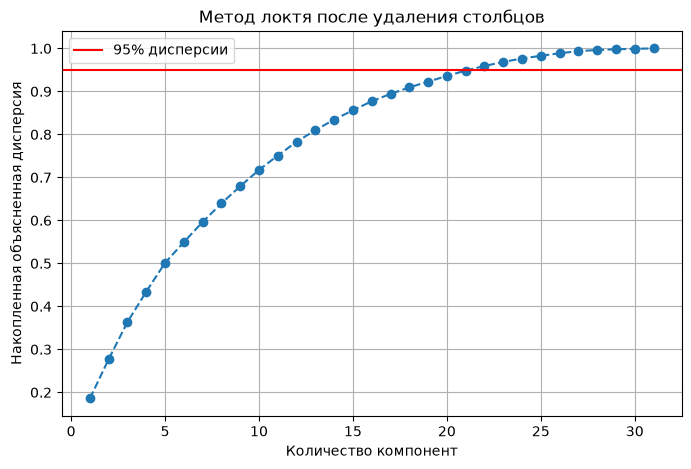

In [20]:
# Для полных данных
# Считаем PCA для всех возможных компонент (48)
X_alltrain_scaled, X_alltest_scaled = prepare(X_train, X_test)
pca_full = PCA().fit(X_alltrain_scaled)

# Считаем накопленную сумму объясненной дисперсии
cumsum = np.cumsum(pca_full.explained_variance_ratio_)

# Визуализация
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumsum) + 1), cumsum, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% дисперсии')
plt.xlabel('Количество компонент')
plt.ylabel('Накопленная объясненная дисперсия')
plt.title('Метод локтя до удаления столбцов')
plt.grid(True)
plt.legend()
plt.savefig('elbow_method1.png')
plt.show()


# После удаления столбцов
# Считаем PCA для всех возможных компонент (48)
pca_full = PCA().fit(X_train_scaled)

# Считаем накопленную сумму объясненной дисперсии
cumsum = np.cumsum(pca_full.explained_variance_ratio_)

# Визуализация
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumsum) + 1), cumsum, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% дисперсии')
plt.xlabel('Количество компонент')
plt.ylabel('Накопленная объясненная дисперсия')
plt.title('Метод локтя после удаления столбцов')
plt.grid(True)
plt.legend()
plt.savefig('elbow_method2.png')
plt.show()

5) Визуализация

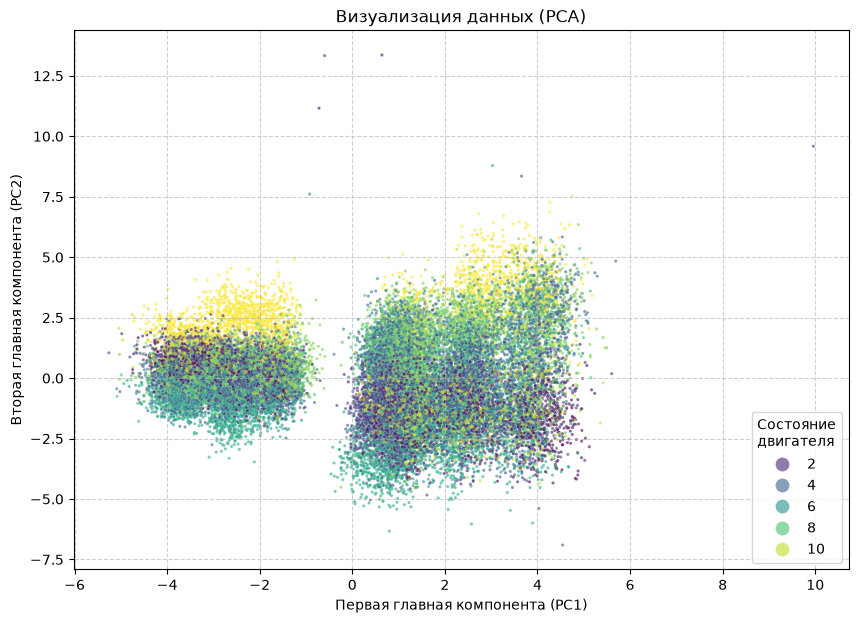

Объясненная дисперсия: [0.21567379 0.095375  ]
Общая объясненная дисперсия (в процентах): 31.10%
Г4 опровергнута


In [21]:
# Готовая нормализация
X_train_scaled, X_test_scaled = prepare(X_train_reduced, X_test_reduced)


'''# БЕЗ УДАЛЕНИЯ ПАРАМЕТРОВ
# PCA визуализация с выбросами
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train, palette='viridis', alpha=0.6, s=5, linewidth=0.1)
handles, labels = scatter.get_legend_handles_labels()
for handle in handles:
    handle.set_markersize(10)
plt.title("Визуализация данных (PCA, без удаления выбросов, все параметры)")
plt.xlabel("Первая главная компонента (PC1)")
plt.ylabel("Вторая главная компонента (PC2)")
legend = plt.legend(title="Состояние\nдвигателя", loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.savefig('pca_plot.png')
plt.show()'''


# С УДАЛЕНИЕМ ПАРАМЕТРОВ
# PCA визуализация без выбросов

# Маска выбросов
mask = outliers(X_train_reduced, X_train_reduced)
rows_with_outliers = mask.any(axis=1)

# Оставляем только те строки, где выбросов нет
X_train_clean = X_train_reduced[~rows_with_outliers]
y_train_clean = y_train[~rows_with_outliers]

# Нормализация эти «чистых» данных
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train_clean)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train_clean, palette='viridis', alpha=0.6, s=5, linewidth=0.1)
handles, labels = scatter.get_legend_handles_labels()
for handle in handles:
    handle.set_markersize(10)
plt.title("Визуализация данных (PCA)")
plt.xlabel("Первая главная компонента (PC1)")
plt.ylabel("Вторая главная компонента (PC2)")

legend = plt.legend(title="Состояние\nдвигателя", loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('pca_clean_plot_DropOutlets.png')
plt.show()


# Гипотеза Г4: проверка объясненной дисперсии
print(f"Объясненная дисперсия: {pca.explained_variance_ratio_}")
# Общую информация о "качестве" сжатия
total_variance = sum(pca.explained_variance_ratio_)
print(f"Общая объясненная дисперсия (в процентах): {total_variance * 100:.2f}%")
if total_variance >= 0.5:
    print("Г4 подтверждена")
else:
    print("Г4 опровергнута")

Г4 ОПРОВЕРГНУТА: 31.10% < 50%

6. Перепроверка результата

UMAP

C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


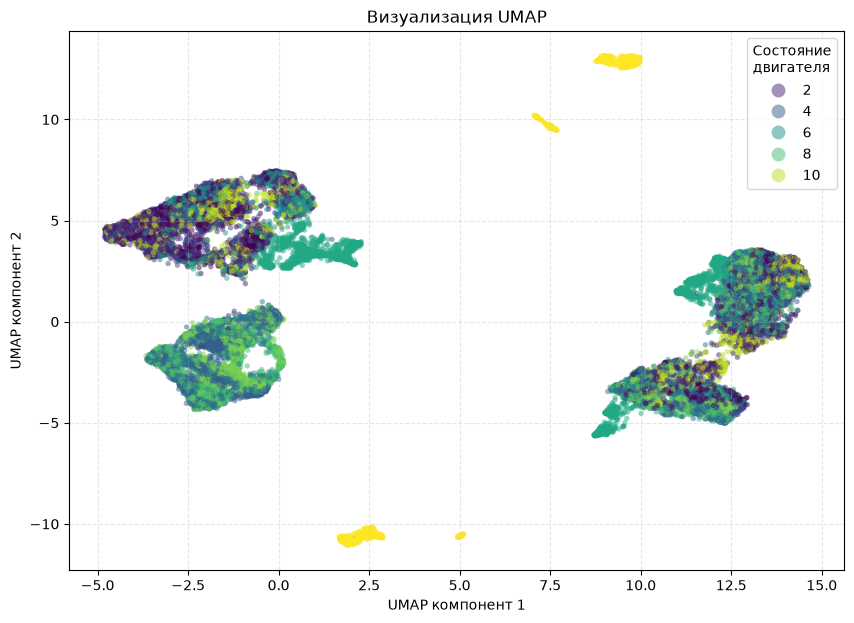

In [25]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=seed)

X_umap = reducer.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=y_train_clean, palette='viridis', alpha=0.5, s=15, linewidth=0)
handles, labels = scatter.get_legend_handles_labels()
for handle in handles:
    handle.set_markersize(10)
plt.xlabel("UMAP компонент 1")
plt.ylabel("UMAP компонент 2")
plt.title("Визуализация UMAP")
plt.legend(title="Состояние\nдвигателя", loc='upper right')
plt.grid(True, linestyle='--', alpha=0.3)

plt.savefig('umap_final.png')
plt.show()

t-NSE

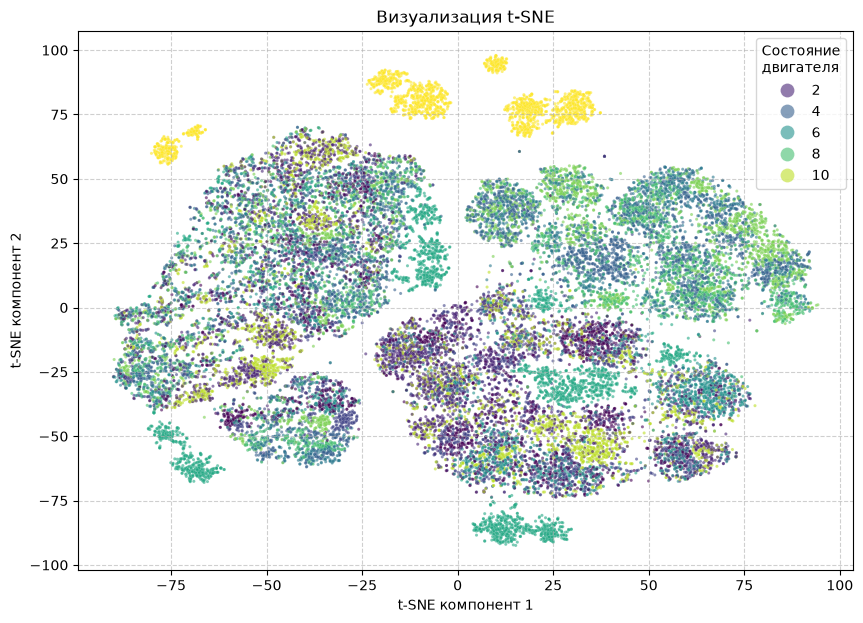

In [23]:
tsne = TSNE(n_components=2, random_state=seed)
X_tsne = tsne.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 7))
scatter = sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_train_clean, palette='viridis', alpha=0.6, s=5, linewidth=0.1)
handles, labels = scatter.get_legend_handles_labels()
for handle in handles:
    handle.set_markersize(10)

plt.title("Визуализация t-SNE")
plt.legend(title="Состояние\nдвигателя", loc='upper right')
plt.xlabel("t-SNE компонент 1")
plt.ylabel("t-SNE компонент 2")
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('tnse.png')
plt.show()


5. Сохранение обрезанных данных

In [24]:
data_reduced = X.drop(columns=to_drop).copy()
data_reduced['cls'] = y
data_reduced.to_csv('data_reduced.csv', index=False)
print("Очищенный файл сохранен в data_reduced.csv")

Очищенный файл сохранен в data_reduced.csv
